<a href="https://colab.research.google.com/github/Sayidullo/bisection-method-calculator/blob/main/AIML302_Lab_Autoencoders(AE)_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML302: Deep Learning and Neural Networks

## Lab: Autoencoders: learning compressed representations, reconstructing images and exploring the 2-D latent space on MNIST

**Duration:** 2 hours

- **Part A (Hour 1):** Guided walkthrough. We build, train and explore an autoencoder together.
- **Part B (Hour 2):** Graded exercises (100 marks). You work on these on your own.

**By the end of this lab you will be able to:**

1. Explain what an autoencoder is and what its three parts (encoder, bottleneck, decoder) do.
2. Build a simple autoencoder in PyTorch using fully connected (Linear) layers.
3. Train it to reconstruct MNIST digit images.
4. Plot the 2-D latent space and explain what it shows.
5. Decode points from the latent space back into images.
6. Compare a 2-D and a 3-D latent space using an interactive plot.

---
# Part A: Guided Walkthrough (Hour 1)

## A1. What is an autoencoder?

An autoencoder is a neural network that learns to **copy its input to its output**.

That sounds useless at first: why train a network to give back what we already have? The trick is that we force the data to pass through a **very small middle layer**. The network cannot simply copy every pixel. It has to learn a short summary of the image and then rebuild the image from that summary.

An autoencoder has three parts:

| Part | What it does | In our lab |
|---|---|---|
| **Encoder** | Squeezes the input into a small set of numbers | 784 pixels become 2 numbers |
| **Bottleneck (latent space)** | The small summary in the middle | 2 numbers per image |
| **Decoder** | Rebuilds the input from the summary | 2 numbers become 784 pixels |

```
  Input image          Encoder         Latent         Decoder        Output image
  (784 pixels)  --->  784 -> 128  ---> (2 numbers) ---> 2 -> 128  ---> (784 pixels)
                           -> 2                              -> 784
```

**A simple way to think about it:** imagine describing a handwritten digit to a friend over the phone using only two numbers. Your friend then has to draw the digit from those two numbers. The encoder is you, the decoder is your friend, and the two numbers are the latent code.

**Important:** we never use the labels (0, 1, 2, ...) to train an autoencoder. The input is also the target. This is called **unsupervised learning**. We will only use the labels at the end, to colour our plots.

**What are autoencoders used for?**
- Compressing data (dimensionality reduction)
- Removing noise from images (denoising)
- Detecting unusual data (anomaly detection): an unusual input gets a poor reconstruction
- They are also the starting point for generative models such as the Variational Autoencoder (VAE)

## A2. Setup

First we import the libraries we need.

- `torch` and `torch.nn`: to build and train the network
- `torchvision`: to download the MNIST dataset
- `matplotlib`: to draw images and plots

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Use the GPU if Colab gives us one, otherwise use the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Fix the random seed so everyone gets similar results
torch.manual_seed(42)

Using device: cuda


## A3. Load the MNIST dataset

MNIST contains 70,000 small grey images of handwritten digits (0 to 9):
- 60,000 images for training
- 10,000 images for testing

Each image is **28 x 28 pixels**. `transforms.ToTensor()` turns each image into a PyTorch tensor and scales every pixel to a value between **0 (black)** and **1 (white)**.

A `DataLoader` gives us the images in small groups called **batches**. Here one batch is 128 images.

In [ ]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 463kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.15MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.16MB/s]

Training images: 60000
Test images: 10000


Let us look at one image and its shape.

The shape is `[1, 28, 28]`: 1 colour channel (grey), 28 rows and 28 columns.

In [ ]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Smallest pixel value:", image.min().item())
print("Largest pixel value:", image.max().item())

Image shape: torch.Size([1, 28, 28])
Label: 5
Smallest pixel value: 0.0
Largest pixel value: 1.0


Now let us draw the first 10 training images.

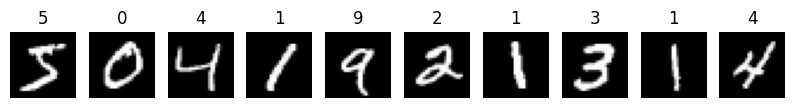

In [ ]:
plt.figure(figsize=(10, 2))
for i in range(10):
    image, label = train_data[i]
    plt.subplot(1, 10, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(label)
    plt.axis("off")
plt.show()

## A4. Flattening the images

Our network uses `nn.Linear` layers. A Linear layer expects each input to be a **flat list of numbers**, not a 2-D grid.

So we flatten each image: 28 x 28 = **784** numbers in one long row.

```
[1, 28, 28]   --->   [784]
```

In PyTorch, `x.view(x.size(0), -1)` does this for a whole batch. The `-1` means "work out this size for me".

In [ ]:
images, labels = next(iter(train_loader))      # take one batch
print("Batch shape before flattening:", images.shape)

flat_images = images.view(images.size(0), -1)
print("Batch shape after flattening: ", flat_images.shape)

Batch shape before flattening: torch.Size([128, 1, 28, 28])
Batch shape after flattening:  torch.Size([128, 784])


## A5. Build the autoencoder

We build the model as a class with two parts:

**Encoder** (784 to 2):
- `Linear(784, 128)` then `ReLU`
- `Linear(128, latent_dim)` gives the latent code (2 numbers)

**Decoder** (2 to 784):
- `Linear(latent_dim, 128)` then `ReLU`
- `Linear(128, 784)` then `Sigmoid`

**Why Sigmoid at the end?** Sigmoid squashes every output into the range 0 to 1. Our pixel values are also between 0 and 1, so the output matches the input.

We give the class a setting called `latent_dim` (the size of the bottleneck). Today we use `latent_dim = 2` so we can draw the latent space on a flat 2-D plot. You will change this number in the exercises.

The `forward` function describes what happens to one batch:
1. Flatten the images
2. Encode them into latent codes
3. Decode the latent codes back into images

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        # Encoder: 784 -> 128 -> latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        # Decoder: latent_dim -> 128 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)   # flatten: [batch, 1, 28, 28] -> [batch, 784]
        z = self.encoder(x)         # encode:  [batch, 784] -> [batch, latent_dim]
        out = self.decoder(z)       # decode:  [batch, latent_dim] -> [batch, 784]
        return out


model = Autoencoder(latent_dim=2).to(device)
print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


Let us check the shapes by passing one batch through the untrained model.

The output has 784 numbers per image, the same as the flattened input. The model has not learned anything yet, so the output is just noise.

In [ ]:
images, labels = next(iter(train_loader))
images = images.to(device)

latent = model.encoder(images.view(images.size(0), -1))
output = model(images)

print("Input shape: ", images.shape)
print("Latent shape:", latent.shape)
print("Output shape:", output.shape)

Input shape:  torch.Size([128, 1, 28, 28])
Latent shape: torch.Size([128, 2])
Output shape: torch.Size([128, 784])


## A6. Loss function and optimizer

**Loss function: Mean Squared Error (MSE)**

We want the output image to look like the input image. MSE measures this:
1. For each pixel, take (output pixel minus input pixel)
2. Square it, so the value is always positive
3. Take the average over all pixels

A **smaller** MSE means a **better** reconstruction.

Notice that the target is the **input image itself**, not the label.

**Optimizer: Adam**

Adam updates the weights to make the loss smaller. The learning rate `lr=0.001` controls how big each update step is.

In [ ]:
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

## A7. Train the autoencoder

We write the training loop as a function so we can use it again in the exercises.

For every batch, the loop does the same five steps you have seen in earlier labs:

1. Move the images to the device
2. **Forward pass:** get the reconstructed images
3. **Compute the loss:** compare the output with the flattened input
4. **Backward pass:** `loss.backward()` computes the gradients
5. **Update:** `optimizer.step()` changes the weights

Remember to call `optimizer.zero_grad()` at the start of each step, so old gradients do not pile up.

Note that we do **not** use `labels` anywhere in training.

One **epoch** means one full pass over all 60,000 training images. We train for 5 epochs. This takes about 1 to 2 minutes on Colab.

In [ ]:
def train_autoencoder(model, optimizer, epochs=5):
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0

        for images, labels in train_loader:          # labels are not used
            images = images.to(device)
            targets = images.view(images.size(0), -1)  # target = the input itself

            optimizer.zero_grad()                    # 1. clear old gradients
            outputs = model(images)                  # 2. forward pass
            loss = loss_fn(outputs, targets)         # 3. compare output with input
            loss.backward()                          # 4. compute gradients
            optimizer.step()                         # 5. update weights

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)
        loss_history.append(average_loss)
        print(f"Epoch {epoch + 1}/{epochs}  -  loss: {average_loss:.4f}")

    return loss_history


loss_history = train_autoencoder(model, optimizer, epochs=5)

Epoch 1/5  -  loss: 0.0630
Epoch 2/5  -  loss: 0.0505
Epoch 3/5  -  loss: 0.0487
Epoch 4/5  -  loss: 0.0475
Epoch 5/5  -  loss: 0.0467


## A8. Plot the training loss

The loss should go **down** over the epochs. This tells us the reconstructions are getting better.

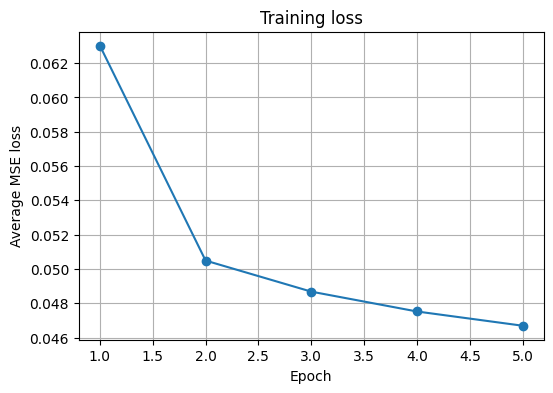

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average MSE loss")
plt.title("Training loss")
plt.grid(True)
plt.show()

## A9. Look at the reconstructions

Now we pass some **test images** (images the model has never seen) through the autoencoder.

- **Top row:** the original images
- **Bottom row:** what the autoencoder rebuilt from only **2 numbers**

We use `model.eval()` and `torch.no_grad()` because we are only testing, not training. This saves memory and time.

We write this as a function `show_reconstructions` so we can use it again later.

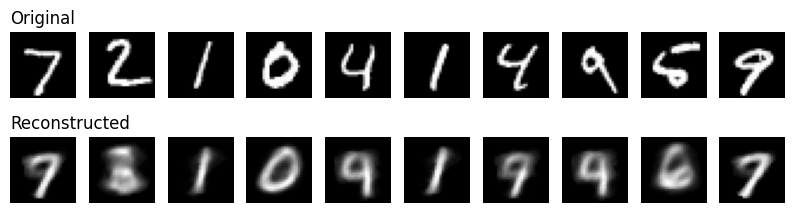

In [ ]:
def show_reconstructions(model, n=10):
    model.eval()
    images, labels = next(iter(test_loader))
    images = images[:n].to(device)

    with torch.no_grad():
        outputs = model(images)

    outputs = outputs.view(n, 28, 28).cpu()   # un-flatten: 784 -> 28 x 28
    images = images.cpu()

    plt.figure(figsize=(n, 2.5))
    for i in range(n):
        # top row: original
        plt.subplot(2, n, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.axis("off")
        if i == 0:
            plt.title("Original", loc="left")

        # bottom row: reconstruction
        plt.subplot(2, n, n + i + 1)
        plt.imshow(outputs[i], cmap="gray")
        plt.axis("off")
        if i == 0:
            plt.title("Reconstructed", loc="left")
    plt.show()


show_reconstructions(model)

**What do you notice?**

- The reconstructions are **blurry**, but most digits are still recognisable.
- Some digits are mixed up (for example a 4 may look like a 9). Two numbers are simply not enough to store every detail.

This is the key idea: the bottleneck forces the model to keep only the **most important** information about each image.

## A10. Explore the 2-D latent space

Every image is now described by just 2 numbers. We can treat these 2 numbers as **(x, y) coordinates** and draw every test image as one dot on a scatter plot.

We colour each dot by its true label. Remember: the model **never saw the labels** during training.

The function `get_latent_codes` runs the encoder on the whole test set and collects the codes and labels.

In [ ]:
def get_latent_codes(model):
    model.eval()
    all_codes = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            codes = model.encoder(images.view(images.size(0), -1))
            all_codes.append(codes.cpu())
            all_labels.append(labels)

    all_codes = torch.cat(all_codes)     # join all batches together
    all_labels = torch.cat(all_labels)
    return all_codes, all_labels


codes, labels = get_latent_codes(model)
print("Latent codes shape:", codes.shape)   # 10,000 images, 2 numbers each

Latent codes shape: torch.Size([10000, 2])


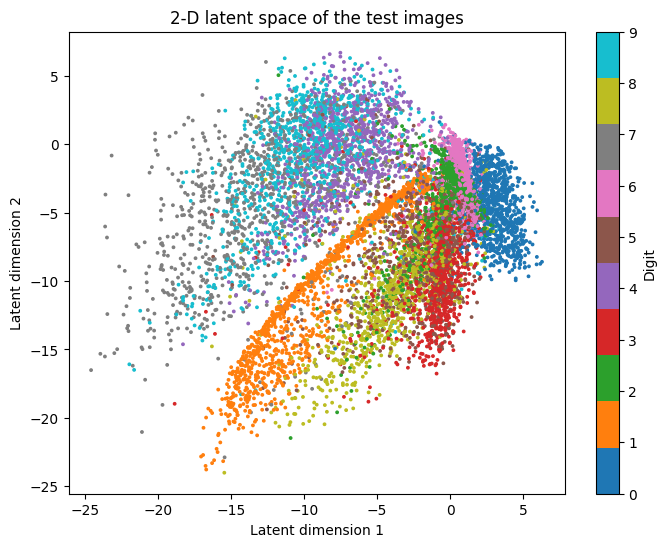

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(codes[:, 0], codes[:, 1], c=labels, cmap="tab10", s=3)
plt.colorbar(label="Digit")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("2-D latent space of the test images")
plt.show()

**How to read this plot:**

- Each dot is one test image. Its position is the 2 numbers the encoder produced.
- Dots of the **same colour form groups (clusters)**. The encoder places similar-looking digits close together, even though it was never told the labels.
- Some groups **overlap** (often 4 and 9, or 3, 5 and 8). These digits look alike, so the model confuses them. This matches the mistakes we saw in the reconstructions.
- There are **empty areas** between and around the groups. No training image was mapped there.

## A11. Decode a point from the latent space

The decoder can turn **any** pair of numbers into an image, not only the codes of real images.

Steps:
1. Choose a point, for example (x, y) = (0, 0)
2. Put it in a tensor of shape `[1, 2]` (1 point, 2 numbers)
3. Pass it through `model.decoder`
4. Reshape the 784 outputs to 28 x 28 and draw it

Below, we first get the average position of each digit's cluster. Then we decode the point at the centre of the "0" cluster.

In [ ]:
# Average latent position of each digit's cluster
for digit in range(10):
    centre = codes[labels == digit].mean(dim=0)
    print(f"Digit {digit}: centre at ({centre[0]:.2f}, {centre[1]:.2f})")

Digit 0: centre at (2.84, -4.58)
Digit 1: centre at (-9.11, -10.98)
Digit 2: centre at (-0.52, -4.37)
Digit 3: centre at (-1.17, -9.19)
Digit 4: centre at (-7.09, -0.85)
Digit 5: centre at (-2.23, -7.97)
Digit 6: centre at (0.55, -2.48)
Digit 7: centre at (-12.59, -4.38)
Digit 8: centre at (-3.99, -10.28)
Digit 9: centre at (-9.72, -1.48)


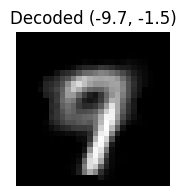

In [ ]:
def decode_point(model, x, y):
    model.eval()
    point = torch.tensor([[x, y]], dtype=torch.float32).to(device)   # shape [1, 2]
    with torch.no_grad():
        image = model.decoder(point)
    return image.view(28, 28).cpu()


centre_of_zero = codes[labels == 9].mean(dim=0)
x, y = centre_of_zero[0].item(), centre_of_zero[1].item()

image = decode_point(model, x, y)
plt.figure(figsize=(2, 2))
plt.imshow(image, cmap="gray")
plt.title(f"Decoded ({x:.1f}, {y:.1f})")
plt.axis("off")
plt.show()

## A12. Walk across the latent space

Now we decode a whole **grid of points**. We take 10 evenly spaced x values and 10 evenly spaced y values, which gives 100 points. We decode each one and draw it in its place.

`torch.linspace(a, b, 10)` gives 10 evenly spaced numbers from `a` to `b`. We use the smallest and largest codes from the scatter plot so the grid covers the whole latent space.

The result is a map that shows what the decoder "draws" at every location.

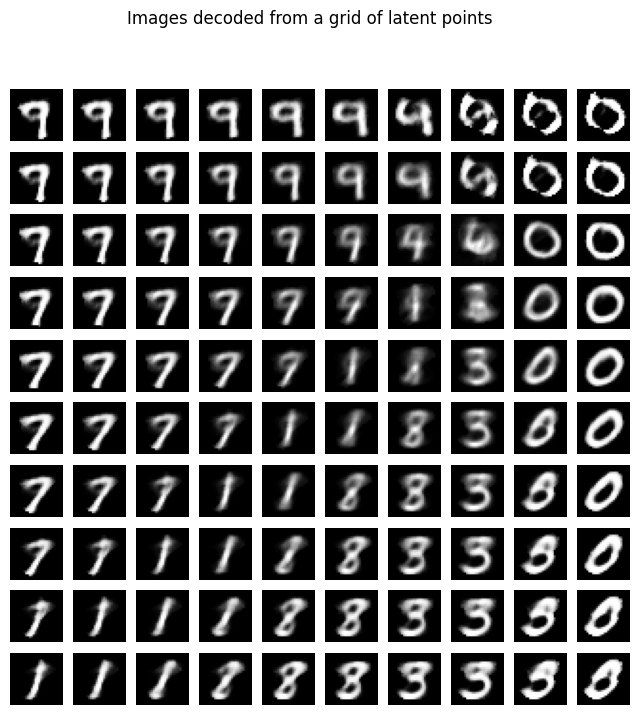

In [ ]:
n = 10
x_values = torch.linspace(codes[:, 0].min(), codes[:, 0].max(), n)
y_values = torch.linspace(codes[:, 1].min(), codes[:, 1].max(), n)

plt.figure(figsize=(8, 8))
for row in range(n):
    for col in range(n):
        x = x_values[col].item()
        y = y_values[n - 1 - row].item()     # start from the top so y goes up the page
        image = decode_point(model, x, y)

        plt.subplot(n, n, row * n + col + 1)
        plt.imshow(image, cmap="gray")
        plt.axis("off")
plt.suptitle("Images decoded from a grid of latent points")
plt.show()

**What do you notice?**

- Digits change **gradually** as you move across the grid. Nearby points decode to similar images.
- Areas that match a cluster in the scatter plot give clear digits.
- Some areas give **unclear or strange shapes**. These are the empty regions in the scatter plot. The decoder was never trained on points there, so it does not know what to draw.

This is the main limitation of a plain autoencoder: it is good at **compressing and rebuilding**, but it is **not reliable at creating new images** from random points. Fixing this problem is what the Variational Autoencoder (VAE) does. We will study it in a later lab.

## A13. Going to 3-D: an interactive latent space

In the 2-D plot some groups overlap. What happens if we give the bottleneck **3 numbers** instead of 2?

With 3 numbers, every image becomes a point in **3-D space (x, y, z)**. The encoder has more room, so the groups can spread out more.

We use the same `Autoencoder` class. We only change `latent_dim` to 3. We give the new model different names (`model_3d`, `codes_3d`, `labels_3d`) so the 2-D model from Part A stays unchanged for the exercises.

Training takes about 1 to 2 minutes, the same as before.

In [ ]:
model_3d = Autoencoder(latent_dim=3).to(device)
optimizer_3d = optim.Adam(model_3d.parameters(), lr=0.001)

loss_history_3d = train_autoencoder(model_3d, optimizer_3d, epochs=5)

print()
print("Final loss with 2 numbers:", round(loss_history[-1], 4))
print("Final loss with 3 numbers:", round(loss_history_3d[-1], 4))

Epoch 1/5  -  loss: 0.0583
Epoch 2/5  -  loss: 0.0437
Epoch 3/5  -  loss: 0.0415
Epoch 4/5  -  loss: 0.0404
Epoch 5/5  -  loss: 0.0395

Final loss with 2 numbers: 0.0467
Final loss with 3 numbers: 0.0395


The loss with 3 numbers should usually be **lower**: one extra number lets the model keep more detail. Let us check the reconstructions.

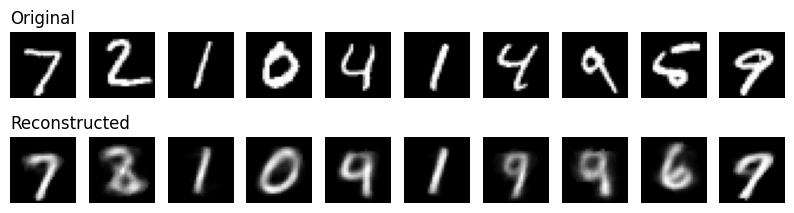

In [ ]:
show_reconstructions(model_3d)

Now we draw the 3-D latent space. A normal matplotlib 3-D plot is hard to read because points hide behind each other. Instead we use **Plotly**, which makes an **interactive** plot:

- **Drag** with the mouse to rotate the plot
- **Scroll** to zoom in and out
- **Hover** over a point to see its digit
- **Click** a digit in the legend to hide it; **double-click** to show only that digit

Plotly is already installed in Google Colab.

`get_latent_codes` works for any latent size, so we can use it again. We turn the labels into text (`"0"`, `"1"`, ...) so that Plotly gives each digit its own colour in the legend.

In [ ]:
import plotly.express as px

codes_3d, labels_3d = get_latent_codes(model_3d)
print("Latent codes shape:", codes_3d.shape)   # 10,000 images, 3 numbers each

fig = px.scatter_3d(
    x=codes_3d[:, 0],
    y=codes_3d[:, 1],
    z=codes_3d[:, 2],
    color=[str(label) for label in labels_3d.tolist()],
    category_orders={"color": [str(d) for d in range(10)]},
    labels={"x": "Latent 1", "y": "Latent 2", "z": "Latent 3", "color": "Digit"},
    title="3-D latent space of the test images (drag to rotate)",
    opacity=0.7,
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(height=650, legend=dict(itemsizing="constant"))
fig.show()

Latent codes shape: torch.Size([10000, 3])


**Things to try with the plot:**

1. Rotate the plot slowly. Do the groups look more separated than in the 2-D plot?
2. Double-click on **4** in the legend, then single-click on **9** to add it. Are 4 and 9 still close together?
3. Do the same for **3, 5 and 8**.

**What you should notice:**

- With 3 numbers, most groups are **more spread out** and easier to tell apart than in 2-D.
- Some digits that **look alike** (4 and 9, or 3, 5 and 8) are still close together. The autoencoder never saw the labels. It only puts images that **look similar** near each other, and these digits really do look similar.
- There is a trade-off: more latent numbers give **better reconstructions**, but beyond 3 numbers we can no longer draw the latent space directly.

## Summary of Part A

| Concept | Key point |
|---|---|
| Autoencoder | A network trained to rebuild its own input |
| Encoder | Compresses 784 pixels into a small latent code |
| Bottleneck | A small layer that forces the model to keep only important information |
| Decoder | Rebuilds the image from the latent code |
| Loss | MSE between the output and the **input** (no labels needed) |
| Latent space | Similar digits end up close together; there are empty gaps between groups |
| 2-D vs 3-D latent | 3 numbers give better reconstructions and more separated groups; look-alike digits still stay close |

---
# Part B: Graded Exercises (Hour 2)

**Total: 100 marks. Suggested time: 30 minutes.**

**Instructions:**
- Run **all** cells in Part A first. The exercises use `Autoencoder`, `train_autoencoder`, `show_reconstructions`, `get_latent_codes`, `decode_point`, `model` and `codes`/`labels` from Part A.
- Write your code where you see `# YOUR CODE HERE`. Replace each `None` with your answer.
- Write your written answers in the markdown cells marked **Your answer:**. Double-click the cell to edit it.
- Before submitting, rename this notebook as `Lab_Autoencoders_YourName_YourID.ipynb`.

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Changing the size of the bottleneck | 35 |
| 2 | Exploring the latent space | 30 |
| 3 | Denoising autoencoder | 35 |
| | **Total** | **100** |

## Exercise 1: Changing the size of the bottleneck (35 marks)

In Part A the bottleneck had only **2** numbers. What happens if we give the model more room?

**(a)** Create a new autoencoder called `model_16` with `latent_dim=16`. Create an Adam optimizer for it with `lr=0.001`. Then train it for **5 epochs** using `train_autoencoder` (the same as the 2-D model, so the comparison is fair). **(10 marks)**

*Hint: look at how `model` and `optimizer` were created in A5 and A6.*

In [ ]:
model_16 = Autoencoder(latent_dim=16).to(device)
optimizer_16 = optim.Adam(model_16.parameters(), lr=0.001)
loss_history_16 = train_autoencoder(model_16, optimizer_16, epochs=10)

Epoch 1/10  -  loss: 0.0482
Epoch 2/10  -  loss: 0.0229
Epoch 3/10  -  loss: 0.0188
Epoch 4/10  -  loss: 0.0174
Epoch 5/10  -  loss: 0.0165
Epoch 6/10  -  loss: 0.0158
Epoch 7/10  -  loss: 0.0153
Epoch 8/10  -  loss: 0.0148
Epoch 9/10  -  loss: 0.0144
Epoch 10/10  -  loss: 0.0141


**(b)** Use `show_reconstructions` to display the reconstructions of `model_16`. **(5 marks)**

TypeError: 'str' object is not callable

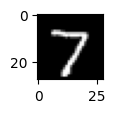

In [ ]:
show_reconstructions(model_16)

**(c)** Print the **final** training loss of the 2-D model (`loss_history`) and of the 16-D model (`loss_history_16`). Which one is lower? **(10 marks)**

*Hint: the last item of a Python list `my_list` is `my_list[-1]`.*

In [ ]:
print(f"Final loss for 2-D model:  {loss_history[-1]:.4f}")
print(f"Final loss for 16-D model: {loss_history_16[-1]:.4f}")

Final loss for 2-D model:  0.0467
Final loss for 16-D model: 0.0141


**(d)** In 2 to 3 sentences: why does the 16-D model give better reconstructions? Why do we still use a 2-D latent space in Part A, even though it is worse at reconstruction? **(10 marks)**

**Your answer:** So 16-D model gives better recontruction because it lets store and pass more data , and its looks more wider but it can be representend using only special tools , but we still using 2-D model because it gives clear X-Y axis representation even if its provides worth recontruction. It gives more understanable visualization to see differences  

## Exercise 2: Exploring the latent space (30 marks)

For this exercise, use the **2-D model from Part A** (`model`) and the `codes` and `labels` you computed in A10.

**(a)** Find the centre (average latent position) of the cluster for digit **1** and the centre for digit **7**. Store them as `centre_1` and `centre_7` and print them. **(5 marks)**

*Hint: look at the first code cell in A11.*

In [ ]:
centre_1 = codes[labels == 1].mean(dim=0)
centre_7 = codes[labels == 7].mean(dim=0)

print("Centre of 1:", centre_1)
print("Centre of 7:", centre_7)

Centre of 1: tensor([ -9.1118, -10.9849])
Centre of 7: tensor([-12.5874,  -4.3830])


**(b)** **Interpolation:** walk in a straight line from `centre_1` to `centre_7` in 8 steps and decode each point. Complete the missing line so the images change smoothly from a 1 into a 7. **(15 marks)**

A point part of the way between two points A and B is:

```
point = A + t * (B - A)
```

- When `t = 0`, the point is A.
- When `t = 1`, the point is B.
- When `t = 0.5`, the point is exactly halfway.

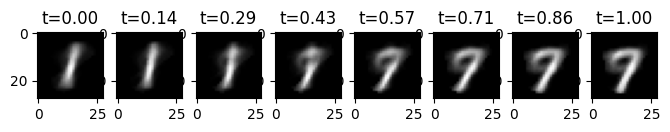

In [ ]:
steps = 8
t_values = torch.linspace(0, 1, steps)

plt.figure(figsize=(steps, 1.5))
for i in range(steps):
    t = t_values[i]

    # compute the point between centre_1 and centre_7
    point = centre_1 + t * (centre_7 - centre_1)

    image = decode_point(model, point[0].item(), point[1].item())
    plt.subplot(1, steps, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"t={t:.2f}")
    plt.axis="off"
plt.show()

**(c)** Look at the scatter plot in A10 and choose a point that lies **far away from all clusters** (an empty area). Decode it with `decode_point` and display the image. Then, in 1 to 2 sentences, describe what you see and explain why. **(10 marks)**

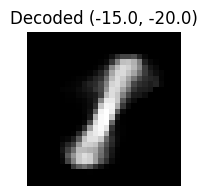

In [ ]:
import matplotlib.pyplot as plt
import sys

# Forcefully reload matplotlib.pyplot to retrieve the original function
import importlib
importlib.reload(plt)

x = -15.0
y = -20.0

image = decode_point(model, x, y)
plt.figure(figsize=(2, 2))
plt.imshow(image, cmap="gray")
plt.title(f"Decoded ({x}, {y})")
plt.axis("off")
plt.show()

**Your answer:** It looks like handwritten 1  

---



## Exercise 3: Denoising autoencoder (35 marks)

A **denoising autoencoder** is trained to **remove noise**:
- **Input:** a noisy image
- **Target:** the clean original image

Because the noise is random, the model cannot just copy its input. It must learn what a real digit looks like.

The function `add_noise` below is already written for you. It adds random noise to the images and keeps every pixel between 0 and 1.

In [ ]:
def add_noise(images, noise_factor=0.4):
    noisy = images + noise_factor * torch.randn_like(images)
    noisy = torch.clamp(noisy, 0.0, 1.0)     # keep pixels between 0 and 1
    return noisy

**(a)** Take one batch from `test_loader`, add noise to it using `add_noise`, and display the first 5 **noisy** images. **(5 marks)**

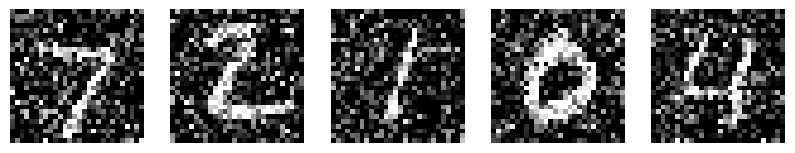

In [ ]:
images, labels = next(iter(test_loader))


noisy_images = add_noise(images)


import matplotlib.pyplot as plt
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(noisy_images[i].squeeze(), cmap="gray")
    plt.axis("off")
plt.show()

**(b)** Complete the training loop below for a denoising autoencoder. Only **two lines** are missing. **(15 marks)**

- The **input** to the model is the **noisy** image.
- The **target** is the **clean** image (flattened).

*Hint: compare with `train_autoencoder` in A7.*

In [ ]:
denoise_model = Autoencoder(latent_dim=16).to(device)
denoise_optimizer = optim.Adam(denoise_model.parameters(), lr=0.001)

epochs = 3
for epoch in range(epochs):
    total_loss = 0
    for images, labels in train_loader:
        images = images.to(device)

        # Create the noisy input
        noisy_images = add_noise(images)

        # Create the target (the CLEAN images, flattened)
        targets = images.view(images.size(0), -1)

        denoise_optimizer.zero_grad()
        outputs = denoise_model(noisy_images)
        loss = loss_fn(outputs, targets)
        loss.backward()
        denoise_optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch + 1}/{epochs}  -  loss: {total_loss / len(train_loader):.4f}")

Epoch 1/3  -  loss: 0.0552
Epoch 2/3  -  loss: 0.0308
Epoch 3/3  -  loss: 0.0261


**(c)** Run the cell below to show **noisy input**, **denoised output** and **clean original** for 8 test images. You do not need to change it. Then, in 1 to 2 sentences, describe how well the model removed the noise. **(5 marks)**

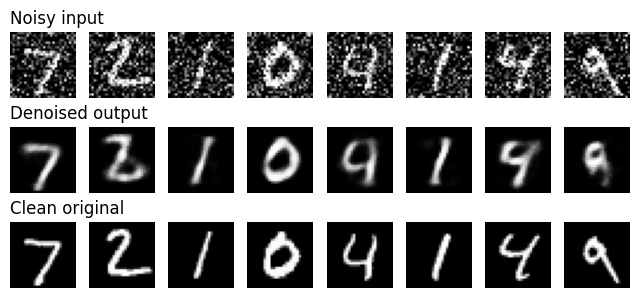

In [ ]:
denoise_model.eval()
images, labels = next(iter(test_loader))
images = images[:8].to(device)
noisy = add_noise(images)

with torch.no_grad():
    denoised = denoise_model(noisy).view(8, 28, 28).cpu()

rows = [noisy.cpu().squeeze(1), denoised, images.cpu().squeeze(1)]
row_names = ["Noisy input", "Denoised output", "Clean original"]

plt.figure(figsize=(8, 3.5))
for r in range(3):
    for i in range(8):
        plt.subplot(3, 8, r * 8 + i + 1)
        plt.imshow(rows[r][i], cmap="gray")
        plt.axis("off")
        if i == 0:
            plt.title(row_names[r], loc="left")
plt.show()

**Your answer:**

**(d)** In 2 to 3 sentences: in a denoising autoencoder, why must the **target** be the clean image and not the noisy image? What would the model learn if the target were the noisy image? **(10 marks)**

**Your answer:** So the target image must be clean because , if there will be noisy its gonna waste capacability of latent space on noisy part which will waste limited capacity of bottleneck and it will  try to encode meaningless pixel fluctuations instead of useful features for downstream tasks

---
**End of lab.** Check that every code cell runs without errors, then save and submit your notebook.